# Исследовательский анализ данных сервиса Яндекс Афиша

**Часть 2. Исследовательский анализ и проверка гипотез**

**Автор проекта: Наместникова Соня**

## Цель проекта

Изучить изменение пользовательского спроса на мероприятия летом и осенью 2024 года, определить наиболее важные регионы и билетных партнёров, а также проверить различия в поведении пользователей мобильных и стационарных устройств.

## Задачи

1. Загрузить данные и проверить их структуру.
2. Найти пропуски, ошибки и дубликаты.
3. Обработать выбросы и привести выручку к рублям.
4. Сравнить структуру заказов летом и осенью.
5. Изучить ежедневную активность пользователей и недельную цикличность.
6. Определить ведущие регионы и билетных партнёров.
7. Проверить две гипотезы о поведении пользователей разных устройств.
8. Подготовить общий вывод и рекомендации.

## Описание данных

В работе используются три файла:

- `final_tickets_orders_df.csv` содержит информацию о заказах с мобильных устройств и стационарных компьютеров;
- `final_tickets_events_df.csv` содержит сведения о мероприятиях, городах, регионах и площадках;
- `final_tickets_tenge_df.csv` содержит курс тенге к российскому рублю. Курс указан для 100 тенге.

Данные о заказах охватывают период с 1 июня по 31 октября 2024 года.

## Структура работы

- загрузка данных и первое знакомство;
- предобработка и объединение таблиц;
- исследовательский анализ;
- проверка статистических гипотез;
- общий вывод и рекомендации.

## Шаг 1. Загрузка данных и знакомство с ними

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import ttest_ind

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

sns.set_theme(style='whitegrid', palette='deep')

In [2]:
# В тренажёре файлы находятся в /datasets.
# Для локального запуска предусмотрены папки data и текущая директория.
candidate_dirs = [Path('/datasets'), Path('data'), Path('.')]
data_dir = next(
    path for path in candidate_dirs
    if (path / 'final_tickets_orders_df.csv').exists()
)

orders_path = data_dir / 'final_tickets_orders_df.csv'
events_path = data_dir / 'final_tickets_events_df.csv'
rates_path = data_dir / 'final_tickets_tenge_df.csv'

orders = pd.read_csv(orders_path)
events = pd.read_csv(events_path)
rates = pd.read_csv(rates_path)

print(f'Заказы: {orders.shape[0]:,} строк, {orders.shape[1]} столбцов')
print(f'События: {events.shape[0]:,} строк, {events.shape[1]} столбцов')
print(f'Курсы валют: {rates.shape[0]:,} строк, {rates.shape[1]} столбца')

Заказы: 290,849 строк, 14 столбцов
События: 22,427 строк, 11 столбцов
Курсы валют: 357 строк, 4 столбца


In [3]:
display(orders.head())
display(events.head())
display(rates.head())

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,"1,521.94",Край билетов,4,"10,870.99",NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,"2,067.51",NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,"1,258.57",За билетом!,4,"13,984.16",75.00
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,"1,390.41",Билеты без проблем,3,"10,695.43",83.00


,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


,data,nominal,curs,cdx
0,2024-01-10,100,19.94,kzt
1,2024-01-11,100,19.73,kzt
2,2024-01-12,100,19.58,kzt
3,2024-01-13,100,19.45,kzt
4,2024-01-14,100,19.45,kzt


In [4]:
for name, table in {'orders': orders, 'events': events, 'rates': rates}.items():
    print(f'\n{name.upper()}')
    table.info()


ORDERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), obj

In [5]:
overview = pd.DataFrame({
    'строки': [len(orders), len(events), len(rates)],
    'столбцы': [orders.shape[1], events.shape[1], rates.shape[1]],
    'полные дубли': [orders.duplicated().sum(), events.duplicated().sum(), rates.duplicated().sum()],
    'всего пропусков': [orders.isna().sum().sum(), events.isna().sum().sum(), rates.isna().sum().sum()]
}, index=['orders', 'events', 'rates'])

display(overview)

missing = pd.concat(
    {
        'orders': orders.isna().sum(),
        'events': events.isna().sum(),
        'rates': rates.isna().sum()
    },
    axis=1
).fillna(0).astype(int)

display(missing[missing.sum(axis=1) > 0])

,строки,столбцы,полные дубли,всего пропусков
orders,290849,14,0,21940
events,22427,11,0,0
rates,357,4,0,0


,orders,events,rates
days_since_prev,21940,0,0


In [6]:
print('Уникальных order_id:', orders['order_id'].nunique())
print('Повторяющихся order_id:', orders['order_id'].duplicated().sum())
print('Уникальных event_id в таблице событий:', events['event_id'].nunique())
print('Повторяющихся event_id:', events['event_id'].duplicated().sum())

print('\nПериод заказов:')
print(orders['created_dt_msk'].min(), '-', orders['created_dt_msk'].max())

print('\nВалюты:')
display(orders['currency_code'].value_counts())

print('Типы устройств:')
display(orders['device_type_canonical'].value_counts())

Уникальных order_id: 290849
Повторяющихся order_id: 0
Уникальных event_id в таблице событий: 22427
Повторяющихся event_id: 0

Период заказов:
2024-06-01 - 2024-10-31

Валюты:


rub    285780
kzt      5069
Name: currency_code, dtype: int64

Типы устройств:


mobile     232679
desktop     58170
Name: device_type_canonical, dtype: int64

### Промежуточный вывод

В таблице заказов 290 849 строк, в таблице событий 22 427 строк, а в таблице курсов валют 357 строк. Идентификаторы заказов и событий уникальны. Полных дубликатов не обнаружено.

Пропуски есть только в `days_since_prev`. Это ожидаемо, так как для первой покупки пользователя нельзя рассчитать количество дней с предыдущего заказа. Период данных соответствует описанию. В таблице присутствуют только два нужных типа устройств и две валюты.

На этапе предобработки нужно преобразовать даты, проверить неявные дубликаты, изучить категориальные значения и распределения количественных признаков. Выручку необходимо анализировать отдельно для рублей и тенге.

## Шаг 2. Предобработка данных и подготовка к исследованию

### Преобразование типов данных

In [7]:
orders['created_dt_msk'] = pd.to_datetime(orders['created_dt_msk'])
orders['created_ts_msk'] = pd.to_datetime(orders['created_ts_msk'])
rates['data'] = pd.to_datetime(rates['data'])

print(orders[['created_dt_msk', 'created_ts_msk']].dtypes)
print('Период курса:', rates['data'].min().date(), '-', rates['data'].max().date())

created_dt_msk    datetime64[ns]
created_ts_msk    datetime64[ns]
dtype: object
Период курса: 2024-01-10 - 2024-12-31


### Проверка категориальных значений

In [8]:
order_categories = [
    'cinema_circuit', 'age_limit', 'currency_code',
    'device_type_canonical', 'service_name'
]

for column in order_categories:
    print(f'\n{column}: {orders[column].nunique()} уникальных значений')
    display(orders[column].value_counts(dropna=False).head(40))


cinema_circuit: 6 уникальных значений


нет           289451
Другое          1261
КиноСити         122
Москино            7
Киномакс           7
ЦентрФильм         1
Name: cinema_circuit, dtype: int64


age_limit: 5 уникальных значений


16    78579
12    62557
0     61487
6     52173
18    36053
Name: age_limit, dtype: int64


currency_code: 2 уникальных значений


rub    285780
kzt      5069
Name: currency_code, dtype: int64


device_type_canonical: 2 уникальных значений


mobile     232679
desktop     58170
Name: device_type_canonical, dtype: int64


service_name: 36 уникальных значений


Билеты без проблем        63709
Лови билет!               41126
Билеты в руки             40364
Мой билет                 34843
Облачко                   26642
Лучшие билеты             17795
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру             1616
Восьмёрка                  1118
Crazy ticket!               790
Росбилет                    539
Шоу начинается!             499
Быстрый кассир              381
Радио ticket                376
Телебилет                   321
КарандашРУ                  133
Реестр                      125
Билет по телефону            85
Вперёд!                      80
Дырокол                      74
Кино билет                   67
Цвет и б

In [9]:
for column in ['event_type_main', 'event_type_description']:
    print(f'\n{column}: {events[column].nunique()} уникальных значений')
    display(events[column].value_counts(dropna=False))

placeholder_values = {'', 'нет', 'неизвестно', 'unknown', 'none', 'nan'}
event_text_columns = events.select_dtypes(include='object').columns

placeholders = {
    column: events[column].astype(str).str.strip().str.lower().isin(placeholder_values).sum()
    for column in event_text_columns
}
display(pd.Series(placeholders, name='значения-заглушки'))


event_type_main: 7 уникальных значений


концерты    8680
театр       7076
другое      4658
спорт        872
стендап      636
выставки     290
ёлки         215
Name: event_type_main, dtype: int64


event_type_description: 20 уникальных значений


концерт                   8485
спектакль                 6015
событие                   4530
шоу                        731
спортивное мероприятие     575
балет                      484
мюзикл                     359
спорт                      297
опера                      252
фестиваль                  212
выставка                   209
ёлка                       157
цирковое шоу               112
экскурсия                    3
оперетта                     1
музыкальный спектакль        1
подарок                      1
снегурочка                   1
кукольный спектакль          1
рок-мюзикл                   1
Name: event_type_description, dtype: int64

event_name                0
event_type_description    0
event_type_main           0
organizers                0
region_name               0
city_name                 0
venue_name                0
venue_address             0
Name: значения-заглушки, dtype: int64

Категории записаны единообразно. Значение `нет` в поле `cinema_circuit` не является пропуском. Оно означает, что заказ не относится к сети кинотеатров. В остальных текстовых полях пустые значения и стандартные заглушки не обнаружены, поэтому дополнительная нормализация категорий не требуется.

### Проверка явных и неявных дубликатов

In [10]:
print('Полные дубликаты заказов:', orders.duplicated().sum())
print('Дубликаты order_id:', orders['order_id'].duplicated().sum())

# order_id является техническим идентификатором, а days_since_prev рассчитанным признаком.
# Поэтому при поиске повторных бронирований эти два поля не учитываются.
booking_columns = [
    column for column in orders.columns
    if column not in ['order_id', 'days_since_prev']
]

implicit_duplicate_mask = orders.duplicated(
    subset=booking_columns,
    keep=False
)

print('Строк в группах неявных дубликатов:', implicit_duplicate_mask.sum())
print('Лишних повторных строк:', orders.duplicated(subset=booking_columns).sum())

display(
    orders.loc[implicit_duplicate_mask]
    .sort_values(booking_columns)
    .head(10)
)

Полные дубликаты заказов: 0
Дубликаты order_id: 0
Строк в группах неявных дубликатов: 77
Лишних повторных строк: 40


,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
11777,1123983,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,Билеты в руки,1,997.48,0.00
11778,1123867,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,Билеты в руки,1,997.48,0.00
26894,1930705,0dc525d7bacbb0d,2024-07-31,2024-07-31 13:26:11,393430,нет,18,rub,desktop,"1,556.05",Лови билет!,3,"19,450.63",11.00
26896,1930763,0dc525d7bacbb0d,2024-07-31,2024-07-31 13:26:11,393430,нет,18,rub,desktop,"1,556.05",Лови билет!,3,"19,450.63",0.00
53715,1935113,206ea45ec11d478,2024-10-29,2024-10-29 16:46:54,442183,нет,16,rub,mobile,601.69,Билеты в руки,2,"6,016.94",32.00
53717,1935171,206ea45ec11d478,2024-10-29,2024-10-29 16:46:54,442183,нет,16,rub,mobile,601.69,Билеты в руки,2,"6,016.94",0.00
57217,160922,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,Лови билет!,2,280.81,0.00
57220,160893,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,Лови билет!,2,280.81,0.00
68214,3326185,2ecf0a4e24cae13,2024-10-17,2024-10-17 15:25:33,481392,нет,18,rub,mobile,40.33,Билеты без проблем,2,"1,008.14",7.00
68215,3326272,2ecf0a4e24cae13,2024-10-17,2024-10-17 15:25:33,481392,нет,18,rub,mobile,40.33,Билеты без проблем,2,"1,008.14",0.00


In [11]:
rows_before_duplicates = len(orders)

orders = orders.drop_duplicates(
    subset=booking_columns,
    keep='first'
).copy()

print('Удалено неявных дубликатов:', rows_before_duplicates - len(orders))

# После удаления повторов пересчитываем интервал между покупками.
orders = orders.sort_values(['user_id', 'created_ts_msk', 'order_id'])
orders['days_since_prev'] = (
    orders.groupby('user_id')['created_dt_msk']
    .diff()
    .dt.days
    .astype('Int16')
)

print('Пропусков в days_since_prev после пересчёта:', orders['days_since_prev'].isna().sum())

Удалено неявных дубликатов: 40
Пропусков в days_since_prev после пересчёта: 21940


Найдено 40 лишних строк, у которых совпадают пользователь, время, мероприятие, устройство, количество билетов и финансовые показатели. Различаются только идентификаторы заказа. Такие записи больше похожи на технические повторы, поэтому оставлена одна запись из каждой группы. После удаления повторов показатель `days_since_prev` пересчитан.

### Объединение заказов и событий

In [12]:
rows_before_merge = len(orders)

df = orders.merge(
    events,
    on='event_id',
    how='inner',
    validate='many_to_one'
)

missing_event_rows = rows_before_merge - len(df)

print('Строк до объединения:', rows_before_merge)
print('Строк после объединения:', len(df))
print('Не вошло заказов:', missing_event_rows)
print('Пропусков после объединения, кроме days_since_prev:')
display(df.drop(columns='days_since_prev').isna().sum().loc[lambda x: x > 0])

Строк до объединения: 290809
Строк после объединения: 290571
Не вошло заказов: 238
Пропусков после объединения, кроме days_since_prev:


Series([], dtype: int64)

После объединения не вошло 238 заказов. В SQL-запросе для таблицы событий были исключены фильмы, поэтому для этих заказов нет соответствующей строки в `events`. Для дальнейшего анализа используются только заказы, для которых доступна информация о мероприятии.

### Исследование выручки и количества билетов

In [13]:
revenue_stats = (
    df.groupby('currency_code', observed=True)['revenue']
    .describe(percentiles=[0.01, 0.50, 0.90, 0.95, 0.99, 0.999])
)
display(revenue_stats)

display(
    df['tickets_count']
    .describe(percentiles=[0.01, 0.50, 0.90, 0.95, 0.99, 0.999])
    .to_frame()
)

,count,mean,std,min,1%,50%,90%,95%,99%,99.9%,max
currency_code,,,,,,,,,,,
kzt,"5,068.00","4,995.83","4,917.04",0.00,90.27,"3,698.83","13,212.93","13,784.26","17,617.24","22,021.55","26,425.86"
rub,"285,503.00",548.03,871.78,-90.76,0.00,346.70,"1,276.15","1,607.10","2,570.78","5,140.78","81,174.54"


,tickets_count
count,"290,571.00"
mean,2.75
std,1.17
min,1.00
1%,1.00
50%,3.00
90%,4.00
95%,5.00
99%,6.00
99.9%,6.00


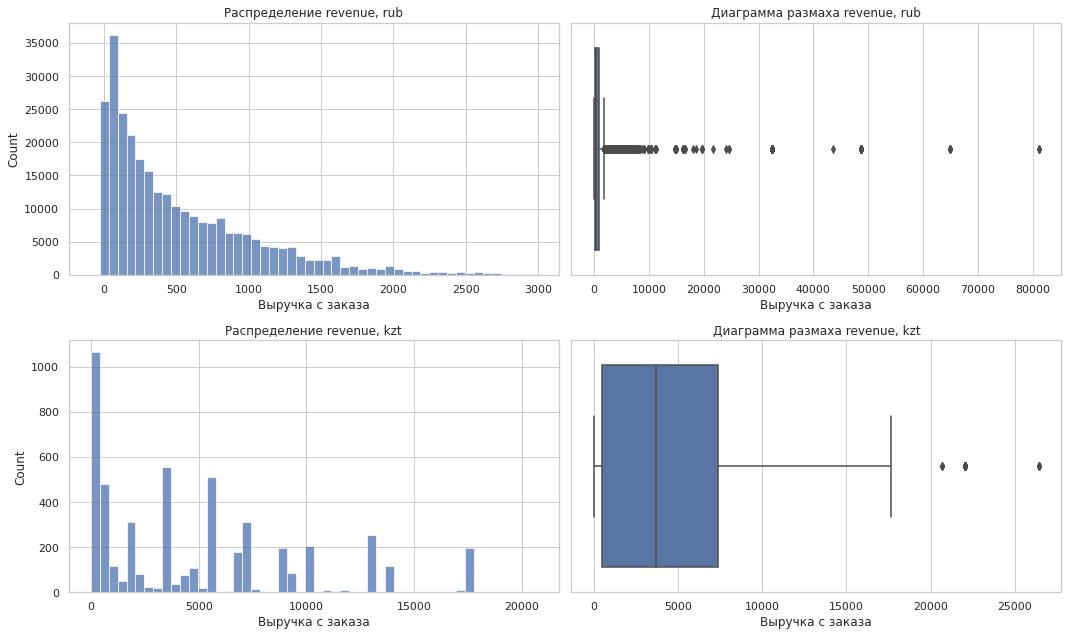

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for row, currency in enumerate(['rub', 'kzt']):
    sample = df.loc[df['currency_code'] == currency, 'revenue']
    display_limit = sample.quantile(0.995)

    sns.histplot(
        sample[sample <= display_limit],
        bins=50,
        ax=axes[row, 0]
    )
    axes[row, 0].set_title(f'Распределение revenue, {currency}')
    axes[row, 0].set_xlabel('Выручка с заказа')

    sns.boxplot(x=sample, ax=axes[row, 1])
    axes[row, 1].set_title(f'Диаграмма размаха revenue, {currency}')
    axes[row, 1].set_xlabel('Выручка с заказа')

plt.tight_layout()
plt.show()

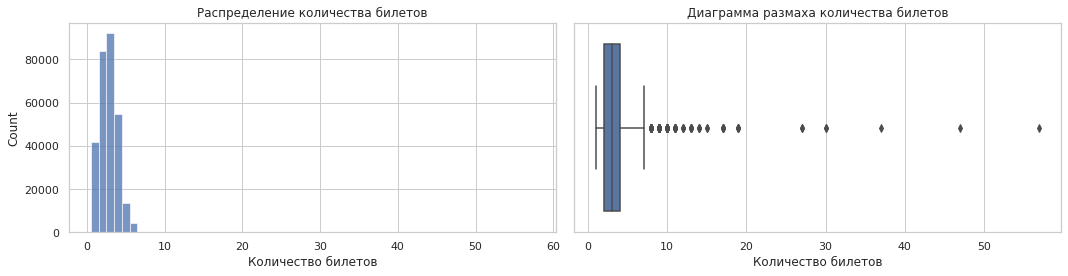

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

sns.histplot(df['tickets_count'], discrete=True, ax=axes[0])
axes[0].set_title('Распределение количества билетов')
axes[0].set_xlabel('Количество билетов')

sns.boxplot(x=df['tickets_count'], ax=axes[1])
axes[1].set_title('Диаграмма размаха количества билетов')
axes[1].set_xlabel('Количество билетов')

plt.tight_layout()
plt.show()

Распределения выручки имеют длинный правый хвост. Максимальные значения значительно превышают медиану, поэтому верхние значения следует ограничить 99-м процентилем отдельно для каждой валюты.

Также обнаружены заказы с нулевой и отрицательной выручкой. В рамках анализа продаж они не отражают обычные оплаченные заказы, поэтому исключаются. В `tickets_count` основная часть значений находится в пределах от 1 до 6, но встречаются отдельные заказы до 57 билетов. Для этого признака также используется граница 99-го процентиля.

In [16]:
rows_before_filtering = len(df)

revenue_limits = (
    df.groupby('currency_code', observed=True)['revenue']
    .quantile(0.99)
)
display(revenue_limits.rename('99-й процентиль revenue'))

nonpositive_revenue = (df['revenue'] <= 0).sum()
revenue_outliers = (
    df['revenue'] > df['currency_code'].map(revenue_limits)
).sum()

valid_revenue = (
    (df['revenue'] > 0)
    & (df['revenue'] <= df['currency_code'].map(revenue_limits))
)
df = df.loc[valid_revenue].copy()

tickets_limit = df['tickets_count'].quantile(0.99)
tickets_outliers = (df['tickets_count'] > tickets_limit).sum()
df = df.loc[df['tickets_count'] <= tickets_limit].copy()

print('Удалено строк с неположительной выручкой:', nonpositive_revenue)
print('Удалено верхних выбросов revenue:', revenue_outliers)
print('Граница tickets_count:', tickets_limit)
print('Удалено выбросов tickets_count:', tickets_outliers)
print('Осталось строк:', len(df))
print('Доля сохранённых строк от объединённой таблицы:', f'{len(df) / rows_before_filtering:.2%}')

currency_code
kzt   17,617.24
rub    2,570.78
Name: 99-й процентиль revenue, dtype: float64

Удалено строк с неположительной выручкой: 5906
Удалено верхних выбросов revenue: 2885
Граница tickets_count: 6.0
Удалено выбросов tickets_count: 174
Осталось строк: 281606
Доля сохранённых строк от объединённой таблицы: 96.91%


### Приведение выручки к рублям

In [17]:
rates_for_merge = rates.rename(columns={
    'data': 'created_dt_msk',
    'cdx': 'currency_code'
})

df = df.merge(
    rates_for_merge[['created_dt_msk', 'currency_code', 'nominal', 'curs']],
    on=['created_dt_msk', 'currency_code'],
    how='left',
    validate='many_to_one'
)

missing_kzt_rates = df.loc[
    df['currency_code'] == 'kzt', 'curs'
].isna().sum()
print('Заказов в тенге без курса:', missing_kzt_rates)

# Для рублёвых заказов коэффициент пересчёта равен 1.
rub_mask = df['currency_code'] == 'rub'
df.loc[rub_mask, ['nominal', 'curs']] = 1

df['revenue_rub'] = (
    df['revenue'] * df['curs'] / df['nominal']
)

display(
    df.groupby('currency_code', observed=True)['revenue_rub']
    .describe()[['count', 'mean', '50%', 'max']]
)

Заказов в тенге без курса: 0


,count,mean,50%,max
currency_code,,,,
kzt,"5,033.00",962.42,734.32,"3,504.56"
rub,"276,573.00",521.04,355.06,"2,569.61"


Для заказов в тенге выручка переведена в рубли по курсу на дату заказа. Поскольку курс указан для 100 тенге, использована формула `revenue * curs / nominal`. Для заказов в рублях коэффициент пересчёта равен единице. Все даты заказов в тенге удалось сопоставить с курсом.

### Создание новых признаков

In [18]:
df['one_ticket_revenue_rub'] = (
    df['revenue_rub'] / df['tickets_count']
)

df['month'] = (
    df['created_dt_msk']
    .dt.to_period('M')
    .dt.to_timestamp()
)

season_by_month = {
    12: 'зима', 1: 'зима', 2: 'зима',
    3: 'весна', 4: 'весна', 5: 'весна',
    6: 'лето', 7: 'лето', 8: 'лето',
    9: 'осень', 10: 'осень', 11: 'осень'
}
df['season'] = df['created_dt_msk'].dt.month.map(season_by_month)

display(
    df[[
        'created_dt_msk', 'currency_code', 'revenue',
        'revenue_rub', 'tickets_count',
        'one_ticket_revenue_rub', 'month', 'season'
    ]].head()
)

,created_dt_msk,currency_code,revenue,revenue_rub,tickets_count,one_ticket_revenue_rub,month,season
0,2024-08-20,rub,"1,521.94","1,521.94",4,380.49,2024-08-01,лето
1,2024-07-23,rub,"1,902.42","1,902.42",5,380.48,2024-07-01,лето
2,2024-07-23,rub,"1,141.45","1,141.45",3,380.48,2024-07-01,лето
3,2024-07-23,rub,"1,141.45","1,141.45",3,380.48,2024-07-01,лето
4,2024-07-23,rub,"1,521.94","1,521.94",4,380.49,2024-07-01,лето


### Снижение размерности и итоговая проверка

In [19]:
memory_before = df.memory_usage(deep=True).sum() / 1024**2

integer_columns = ['order_id', 'event_id', 'city_id', 'venue_id']
for column in integer_columns:
    df[column] = pd.to_numeric(df[column], downcast='integer')

df['age_limit'] = pd.to_numeric(df['age_limit'], downcast='integer')
df['tickets_count'] = pd.to_numeric(df['tickets_count'], downcast='integer')

category_columns = df.select_dtypes(include='object').columns
for column in category_columns:
    df[column] = df[column].astype('category')

df['season'] = df['season'].astype('category')

memory_after = df.memory_usage(deep=True).sum() / 1024**2

print(f'Память до оптимизации: {memory_before:.2f} МБ')
print(f'Память после оптимизации: {memory_after:.2f} МБ')
print(f'Экономия памяти: {1 - memory_after / memory_before:.1%}')

Память до оптимизации: 465.31 МБ
Память после оптимизации: 37.84 МБ
Экономия памяти: 91.9%


In [20]:
print('Итоговый размер датафрейма:', df.shape)
print('Повторяющихся order_id:', df['order_id'].duplicated().sum())
print('Полных дубликатов:', df.duplicated().sum())

final_missing = df.isna().sum()
display(final_missing[final_missing > 0].to_frame('пропуски'))

display(
    df[['revenue_rub', 'one_ticket_revenue_rub', 'tickets_count']]
    .describe()
)

display(df['season'].value_counts())
display(df['month'].value_counts().sort_index())

Итоговый размер датафрейма: (281606, 30)
Повторяющихся order_id: 0
Полных дубликатов: 0


,пропуски
days_since_prev,21356


,revenue_rub,one_ticket_revenue_rub,tickets_count
count,"281,606.00","281,606.00","281,606.00"
mean,528.92,195.00,2.74
std,514.24,167.71,1.14
min,0.02,0.02,1.00
25%,122.61,49.94,2.00
50%,358.03,153.47,3.00
75%,797.02,306.58,3.00
max,"3,504.56","2,438.27",6.00


осень    167745
лето     113861
Name: season, dtype: int64

2024-06-01    32882
2024-07-01    37851
2024-08-01    43128
2024-09-01    68820
2024-10-01    98925
Name: month, dtype: int64

In [21]:
# При необходимости подготовленный датафрейм можно сохранить:
# df.to_csv('final_tickets_clean.csv', index=False)

### Промежуточный вывод по предобработке

В ходе предобработки были выполнены следующие действия:

- даты приведены к типу `datetime`;
- удалено 40 неявных дубликатов бронирований;
- после удаления дублей пересчитан показатель `days_since_prev`;
- таблица заказов объединена с информацией о событиях;
- исключено 238 заказов, для которых в таблице событий не было данных;
- удалены заказы с неположительной выручкой;
- верхние выбросы выручки отфильтрованы по 99-му процентилю отдельно для рублей и тенге;
- заказы с аномально большим количеством билетов отфильтрованы по 99-му процентилю;
- выручка в тенге пересчитана в рубли по курсу на дату заказа;
- созданы столбцы `revenue_rub`, `one_ticket_revenue_rub`, `month` и `season`;
- оптимизированы типы данных.

После всех преобразований осталось 281 606 строк, что составляет около 96,8% от исходной таблицы заказов. Пропуски сохранились только в `days_since_prev` для первых покупок пользователей. Данные готовы к исследовательскому анализу и проверке гипотез.

## Шаг 3. Исследовательский анализ данных

### 3.1. Распределение заказов по сегментам и сезонные изменения

#### Количество заказов по месяцам

In [ ]:
monthly_orders = (
    df.groupby('month', observed=True)['order_id']
    .nunique()
    .reset_index(name='orders')
)

display(monthly_orders)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=monthly_orders,
    x='month',
    y='orders',
    color='#4C78A8'
)
ax.set_title('Количество заказов по месяцам')
ax.set_xlabel('Месяц')
ax.set_ylabel('Количество заказов')
ax.set_xticklabels(monthly_orders['month'].dt.strftime('%Y-%m'))
for patch, value in zip(ax.patches, monthly_orders['orders']):
    ax.text(
        patch.get_x() + patch.get_width() / 2,
        patch.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.show()

Количество заказов увеличивалось каждый месяц. В июне было оформлено 32 882 заказа, а в октябре 98 925. За этот период показатель вырос примерно в три раза. Ноябрь в датасете отсутствует, поэтому динамика рассматривается с июня по октябрь включительно.

#### Сравнение структуры заказов летом и осенью

In [ ]:
def calculate_season_shares(data, category):
    shares = pd.crosstab(
        data[category],
        data['season'],
        normalize='columns'
    ) * 100
    return shares.reindex(columns=['лето', 'осень'])


segment_fields = {
    'event_type_main': 'Тип мероприятия',
    'device_type_canonical': 'Тип устройства',
    'age_limit': 'Возрастное ограничение'
}

season_share_tables = {}

fig, axes = plt.subplots(3, 1, figsize=(14, 18))

for ax, (field, title) in zip(axes, segment_fields.items()):
    shares = calculate_season_shares(df, field)
    shares['изменение, п.п.'] = shares['осень'] - shares['лето']
    season_share_tables[field] = shares

    shares[['лето', 'осень']].plot(
        kind='bar',
        ax=ax,
        color=['#72B7B2', '#F58518']
    )
    ax.set_title(f'Распределение заказов: {title.lower()}')
    ax.set_xlabel('')
    ax.set_ylabel('Доля заказов, %')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(title='Сезон')

plt.tight_layout()
plt.show()

for field, title in segment_fields.items():
    print(title)
    display(season_share_tables[field].round(2))

Осенью структура спроса изменилась сильнее всего по типам мероприятий. Доля спорта выросла на 8,76 процентного пункта, а театра на 4,65 процентного пункта. Доли концертов и категории «другое» снизились на 6,53 и 5,52 процентного пункта соответственно.

Распределение по устройствам изменилось незначительно. На мобильные устройства по-прежнему приходится около 80% заказов, хотя доля стационарных компьютеров выросла на 1,28 процентного пункта.

Среди возрастных категорий заметнее всего выросла доля событий 0+, на 5,28 процентного пункта. Доли событий 16+ и 18+ уменьшились.

#### Изменение средней выручки с одного билета

In [ ]:
ticket_revenue_by_type = df.pivot_table(
    index='event_type_main',
    columns='season',
    values='one_ticket_revenue_rub',
    aggfunc='mean',
    observed=True
).reindex(columns=['лето', 'осень'])

ticket_revenue_by_type['изменение, %'] = (
    ticket_revenue_by_type['осень']
    / ticket_revenue_by_type['лето']
    - 1
) * 100

display(ticket_revenue_by_type.round(2).sort_values('изменение, %', ascending=False))

plot_data = ticket_revenue_by_type['изменение, %'].sort_values()
colors = np.where(plot_data >= 0, '#54A24B', '#E45756')

plt.figure(figsize=(10, 6))
ax = plot_data.plot(kind='barh', color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Изменение средней выручки с одного билета осенью')
ax.set_xlabel('Изменение относительно лета, %')
ax.set_ylabel('Тип мероприятия')
plt.tight_layout()
plt.show()

Осенью средняя выручка с одного билета выросла только у выставок и стендапа, примерно на 6%. По остальным типам мероприятий показатель снизился. Самое заметное снижение наблюдается у театра, на 18,62%, у ёлок, на 15,43%, и у концертов, на 13,35%.

Таким образом, рост общего числа заказов осенью сопровождался изменением структуры спроса и снижением средней выручки с билета в большинстве категорий.

### 3.2. Осенняя активность пользователей

#### Динамика показателей по дням

In [ ]:
autumn = df.loc[df['season'] == 'осень'].copy()

daily_activity = (
    autumn.groupby('created_dt_msk', observed=True)
    .agg(
        orders=('order_id', 'nunique'),
        dau=('user_id', 'nunique'),
        avg_ticket_revenue=('one_ticket_revenue_rub', 'mean')
    )
    .reset_index()
)

daily_activity['orders_per_user'] = (
    daily_activity['orders'] / daily_activity['dau']
)

display(daily_activity.head())
display(
    daily_activity[
        ['orders', 'dau', 'orders_per_user', 'avg_ticket_revenue']
    ].describe().round(2)
)

daily_metrics = {
    'orders': 'Количество заказов',
    'dau': 'Активные пользователи, DAU',
    'orders_per_user': 'Заказов на пользователя',
    'avg_ticket_revenue': 'Средняя выручка с билета, руб.'
}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (metric, title) in zip(axes.flat, daily_metrics.items()):
    sns.lineplot(
        data=daily_activity,
        x='created_dt_msk',
        y=metric,
        ax=ax,
        color='#4C78A8'
    )
    ax.set_title(title)
    ax.set_xlabel('Дата')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

Осенью в среднем оформлялось около 2 750 заказов в день, а средний DAU составлял 919 пользователей. На одного активного пользователя приходилось в среднем 2,96 заказа. На графиках видны отдельные пики активности, поэтому дополнительно рассмотрим показатели по дням недели.

#### Недельная цикличность

In [ ]:
weekday_names = {
    0: 'Пн', 1: 'Вт', 2: 'Ср', 3: 'Чт',
    4: 'Пт', 5: 'Сб', 6: 'Вс'
}

daily_activity['weekday_num'] = daily_activity['created_dt_msk'].dt.dayofweek
daily_activity['weekday'] = daily_activity['weekday_num'].map(weekday_names)
daily_activity['day_type'] = np.where(
    daily_activity['weekday_num'] < 5,
    'будни',
    'выходные'
)

weekday_activity = (
    daily_activity.groupby(['weekday_num', 'weekday'], observed=True)
    .agg(
        days=('created_dt_msk', 'count'),
        orders=('orders', 'mean'),
        dau=('dau', 'mean'),
        orders_per_user=('orders_per_user', 'mean'),
        avg_ticket_revenue=('avg_ticket_revenue', 'mean')
    )
    .reset_index()
    .sort_values('weekday_num')
)

day_type_activity = (
    daily_activity.groupby('day_type', observed=True)[
        ['orders', 'dau', 'orders_per_user', 'avg_ticket_revenue']
    ]
    .mean()
)

display(weekday_activity.round(2))
display(day_type_activity.round(2))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (metric, title) in zip(axes.flat, daily_metrics.items()):
    sns.barplot(
        data=weekday_activity,
        x='weekday',
        y=metric,
        ax=ax,
        color='#F58518'
    )
    ax.set_title(title)
    ax.set_xlabel('День недели')
    ax.set_ylabel('Среднее значение за день')

plt.tight_layout()
plt.show()

В будни активность выше, чем в выходные. В среднем за будний день оформлялось 2 894 заказа, а за выходной 2 376. Средний DAU составлял 935 и 878 пользователей соответственно.

Больше всего заказов приходится на вторник, но средняя выручка с одного билета во вторник ниже, чем в другие дни. В выходные заказов меньше, однако средняя выручка с билета выше: около 197 рублей против 179 рублей в будни. Это может говорить о разной структуре мероприятий и заказов в разные дни недели.

### 3.3. Популярные регионы и билетные партнёры

#### Распределение событий и заказов по регионам

In [ ]:
region_metrics = (
    df.groupby('region_name', observed=True)
    .agg(
        events=('event_id', 'nunique'),
        orders=('order_id', 'nunique')
    )
)

region_metrics['event_share_pct'] = (
    region_metrics['events'] / region_metrics['events'].sum() * 100
)
region_metrics['order_share_pct'] = (
    region_metrics['orders'] / region_metrics['orders'].sum() * 100
)

region_top = region_metrics.sort_values('orders', ascending=False).head(10)
display(region_top.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

region_metrics.nlargest(10, 'events')['events'].sort_values().plot(
    kind='barh', ax=axes[0], color='#72B7B2'
)
axes[0].set_title('Топ-10 регионов по разнообразию событий')
axes[0].set_xlabel('Количество уникальных событий')
axes[0].set_ylabel('')

region_metrics.nlargest(10, 'orders')['orders'].sort_values().plot(
    kind='barh', ax=axes[1], color='#4C78A8'
)
axes[1].set_title('Топ-10 регионов по количеству заказов')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

Каменевский регион является лидером и по разнообразию предложений, и по спросу. На него приходится 26,33% уникальных событий и 30,32% заказов. Североярская область занимает второе место с долями 17,15% и 15,44% соответственно.

Распределение заметно сконцентрировано. Пять ведущих регионов формируют около 52,7% уникальных событий и 60% заказов.

#### Активность билетных партнёров

In [ ]:
partner_metrics = (
    df.groupby('service_name', observed=True)
    .agg(
        events=('event_id', 'nunique'),
        orders=('order_id', 'nunique'),
        revenue_rub=('revenue_rub', 'sum')
    )
)

partner_metrics['event_share_pct'] = (
    partner_metrics['events'] / partner_metrics['events'].sum() * 100
)
partner_metrics['order_share_pct'] = (
    partner_metrics['orders'] / partner_metrics['orders'].sum() * 100
)
partner_metrics['revenue_share_pct'] = (
    partner_metrics['revenue_rub'] / partner_metrics['revenue_rub'].sum() * 100
)

partner_top = partner_metrics.sort_values(
    'revenue_rub', ascending=False
).head(10)
display(partner_top.round(2))

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

partner_metrics.nlargest(10, 'events')['events'].sort_values().plot(
    kind='barh', ax=axes[0], color='#72B7B2'
)
axes[0].set_title('Уникальные события')
axes[0].set_xlabel('Количество')
axes[0].set_ylabel('')

partner_metrics.nlargest(10, 'orders')['orders'].sort_values().plot(
    kind='barh', ax=axes[1], color='#4C78A8'
)
axes[1].set_title('Обработанные заказы')
axes[1].set_xlabel('Количество')
axes[1].set_ylabel('')

partner_metrics.nlargest(10, 'revenue_rub')['revenue_rub'].sort_values().plot(
    kind='barh', ax=axes[2], color='#F58518'
)
axes[2].set_title('Выручка в рублях')
axes[2].set_xlabel('Рубли')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

Партнёр «Билеты без проблем» лидирует по выручке и количеству заказов. На него приходится 16,20% выручки и 20,49% заказов. Самое большое число уникальных событий обслуживает партнёр «Лови билет!», его доля составляет 20,03%.

Пять ведущих партнёров обеспечивают около 65,72% выручки и 62,29% заказов. Таким образом, вклад партнёров распределён неравномерно, но лидерство зависит от выбранного показателя.

## Шаг 4. Статистический анализ данных

Для проверки гипотез используются только осенние данные. Единицей анализа будет пользователь, а не отдельный заказ. Это позволяет избежать ситуации, когда несколько заказов одного человека считаются независимыми наблюдениями.

Часть пользователей оформляла заказы с обоих типов устройств. Для независимости выборок такие пользователи исключаются из статистического сравнения. Для проверки средних используется односторонний t-тест Уэлча. Он не требует равенства дисперсий, а большие размеры выборок позволяют опираться на центральную предельную теорему, несмотря на асимметрию исходных распределений.

Уровень статистической значимости: 5%.

In [ ]:
alpha = 0.05

# Односторонний p-value рассчитываем вручную. Такой вариант работает
# и в старых версиях SciPy, где параметра alternative ещё нет.
def welch_greater(sample_1, sample_2):
    statistic, pvalue_two_sided = ttest_ind(
        sample_1, sample_2, equal_var=False
    )
    if statistic > 0:
        pvalue_one_sided = pvalue_two_sided / 2
    else:
        pvalue_one_sided = 1 - pvalue_two_sided / 2
    return statistic, pvalue_one_sided

autumn_user_devices = (
    autumn.groupby('user_id', observed=True)['device_type_canonical']
    .nunique()
)
mixed_device_users = autumn_user_devices[
    autumn_user_devices > 1
].index

autumn_exclusive = autumn.loc[
    ~autumn['user_id'].isin(mixed_device_users)
].copy()

print('Всего пользователей осенью:', autumn['user_id'].nunique())
print('Пользователей обоих устройств:', len(mixed_device_users))
print('Пользователей в независимых группах:', autumn_exclusive['user_id'].nunique())

### Гипотеза 1. Среднее количество заказов на пользователя

**Нулевая гипотеза H0:** среднее количество заказов на одного мобильного пользователя не выше, чем на одного пользователя стационарного компьютера.

**Альтернативная гипотеза H1:** среднее количество заказов на одного мобильного пользователя выше.

In [ ]:
orders_per_user_device = (
    autumn_exclusive.groupby(
        ['user_id', 'device_type_canonical'], observed=True
    )['order_id']
    .nunique()
    .rename('orders')
    .reset_index()
)

display(
    orders_per_user_device.groupby(
        'device_type_canonical', observed=True
    )['orders'].describe().round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=orders_per_user_device,
    x='device_type_canonical',
    y='orders',
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title('Заказы на пользователя, без крайних значений')
axes[0].set_xlabel('Устройство')
axes[0].set_ylabel('Количество заказов')

order_display_limit = orders_per_user_device['orders'].quantile(0.99)
sns.histplot(
    data=orders_per_user_device.loc[
        orders_per_user_device['orders'] <= order_display_limit
    ],
    x='orders',
    hue='device_type_canonical',
    discrete=True,
    common_norm=False,
    multiple='dodge',
    element='bars',
    shrink=0.8,
    ax=axes[1]
)
axes[1].set_title('Распределение заказов на пользователя')
axes[1].set_xlabel('Количество заказов')

plt.tight_layout()
plt.show()

mobile_orders = orders_per_user_device.loc[
    orders_per_user_device['device_type_canonical'] == 'mobile',
    'orders'
]
desktop_orders = orders_per_user_device.loc[
    orders_per_user_device['device_type_canonical'] == 'desktop',
    'orders'
]

stat_orders, pvalue_orders = welch_greater(
    mobile_orders, desktop_orders
)

print(f't-статистика: {stat_orders:.4f}')
print(f'p-value: {pvalue_orders:.6g}')

if pvalue_orders < alpha:
    print('Нулевая гипотеза отвергается.')
else:
    print('Нет оснований отвергать нулевую гипотезу.')

В выборке 10 868 мобильных пользователей и 1 627 пользователей стационарных компьютеров. Среднее количество заказов составляет 2,87 и 1,97 соответственно. Полученное p-value меньше 0,001, поэтому нулевая гипотеза отвергается.

Данные подтверждают предположение, что среднее количество заказов на одного мобильного пользователя выше.

### Гипотеза 2. Среднее время между заказами

**Нулевая гипотеза H0:** среднее время между заказами мобильных пользователей не выше, чем у пользователей стационарных компьютеров.

**Альтернативная гипотеза H1:** среднее время между заказами мобильных пользователей выше.

Пользователи только с одним заказом не имеют значения `days_since_prev`, поэтому в эту проверку они не входят.

In [ ]:
days_between_orders = (
    autumn_exclusive.dropna(subset=['days_since_prev'])
    .groupby(
        ['user_id', 'device_type_canonical'], observed=True
    )['days_since_prev']
    .mean()
    .rename('avg_days_since_prev')
    .reset_index()
)

display(
    days_between_orders.groupby(
        'device_type_canonical', observed=True
    )['avg_days_since_prev'].describe().round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=days_between_orders,
    x='device_type_canonical',
    y='avg_days_since_prev',
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title('Среднее время между заказами')
axes[0].set_xlabel('Устройство')
axes[0].set_ylabel('Количество дней')

sns.histplot(
    data=days_between_orders,
    x='avg_days_since_prev',
    hue='device_type_canonical',
    bins=40,
    common_norm=False,
    element='step',
    ax=axes[1]
)
axes[1].set_title('Распределение времени между заказами')
axes[1].set_xlabel('Среднее количество дней')

plt.tight_layout()
plt.show()

mobile_days = days_between_orders.loc[
    days_between_orders['device_type_canonical'] == 'mobile',
    'avg_days_since_prev'
].astype(float)
desktop_days = days_between_orders.loc[
    days_between_orders['device_type_canonical'] == 'desktop',
    'avg_days_since_prev'
].astype(float)

stat_days, pvalue_days = welch_greater(
    mobile_days, desktop_days
)

print(f't-статистика: {stat_days:.4f}')
print(f'p-value: {pvalue_days:.6g}')

if pvalue_days < alpha:
    print('Нулевая гипотеза отвергается.')
else:
    print('Нет оснований отвергать нулевую гипотезу.')

В анализ вошёл 7 021 мобильный пользователь и 903 пользователя стационарных компьютеров. Средний интервал между заказами составляет 25,15 дня для мобильных пользователей и 31,17 дня для пользователей стационарных компьютеров.

Для альтернативы о большем интервале у мобильных пользователей p-value практически равно 1. Оснований отвергать нулевую гипотезу нет. Наблюдаемая разница направлена в противоположную сторону: мобильные пользователи в среднем возвращаются за следующим заказом быстрее.

## Шаг 5. Общий вывод и рекомендации

В исследовании использованы данные о заказах Яндекс Афиши с 1 июня по 31 октября 2024 года. После объединения таблиц и предобработки осталось 281 606 заказов. Выручка в тенге была пересчитана в рубли по курсу на дату заказа.

### Основные результаты

- Количество заказов росло каждый месяц. В июне было 32 882 заказа, а в октябре 98 925, то есть примерно в три раза больше.
- Осенью выросли доли спортивных и театральных мероприятий. Доли концертов и категории «другое» снизились, хотя концерты остались крупнейшей категорией.
- Доля мобильных заказов почти не изменилась и осталась около 80%.
- Осенью увеличилась доля мероприятий 0+, а доли категорий 16+ и 18+ уменьшились.
- Средняя выручка с одного билета снизилась в большинстве типов мероприятий. Рост наблюдался только у выставок и стендапа.
- В будни пользователи оформляют больше заказов, чем в выходные. При этом средняя выручка с билета выше в выходные.
- Каменевский регион лидирует по разнообразию мероприятий и количеству заказов. Пять ведущих регионов формируют около 60% всех заказов.
- Партнёр «Билеты без проблем» лидирует по выручке и числу заказов. Пять ведущих партнёров обеспечивают около 66% выручки.

### Результаты проверки гипотез

Первая гипотеза получила статистическое подтверждение. Мобильные пользователи в среднем оформляют больше заказов: 2,87 против 1,97 у пользователей стационарных компьютеров.

Вторая гипотеза не подтвердилась. Среднее время между заказами у мобильных пользователей не выше. Наоборот, в выборке оно меньше: 25,15 дня против 31,17 дня.

### Рекомендации

1. Продолжать развивать мобильный сценарий покупки, так как мобильные устройства дают основную часть заказов, а мобильные пользователи проявляют более высокую повторную активность.
2. Учитывать осенний рост интереса к спорту и театру при планировании промокампаний и ассортимента мероприятий.
3. Дополнительно изучить снижение средней выручки с билета по большинству типов мероприятий. Возможными причинами могут быть изменение ассортимента, цен или доли скидочных предложений.
4. При планировании коммуникаций учитывать недельную цикличность. В будни активность выше, а в выходные выше средняя выручка с одного билета.
5. Снижать зависимость от нескольких ведущих регионов и партнёров. Для этого можно отдельно изучить сегменты с меньшей долей заказов и потенциал их роста.